<a href="https://colab.research.google.com/github/coachengilbert-svg/Laboratoy_Exam/blob/main/IRIG_LABORATOY_EXAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing and splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

### 1. Load and Explore the Dataset
Let's load the telecom churn dataset, display its dimensions, view the column data types, and check for missing values.

In [4]:
df = pd.read_csv('/content/telecom_churn.csv')
print(f"Dataset shape: {df.shape}")
display(df.head())
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset shape: (3333, 21)


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False



Missing values per column:
state                     0
account length            0
area code                 0
phone number              0
international plan        0
voice mail plan           0
number vmail messages     0
total day minutes         0
total day calls           0
total day charge          0
total eve minutes         0
total eve calls           0
total eve charge          0
total night minutes       0
total night calls         0
total night charge        0
total intl minutes        0
total intl calls          0
total intl charge         0
customer service calls    0
churn                     0
dtype: int64


### 2. Preprocessing Pipeline, Stratified Data Splitting, and Feature Engineering
We will dynamically identify numeric and categorical columns. We'll build a preprocessor using `ColumnTransformer` to impute missing values (if any) and encode categorical variables using `OneHotEncoder`. Then, we will perform a stratified train-test split (80% training, 20% testing, `random_state=42`) based on the target variable.

In [5]:
# Identify target variable (commonly named 'Churn' or similar)
target_col = [col for col in df.columns if 'churn' in col.lower()]
if not target_col:
    # Fallback to the last column if target name isn't clearly 'churn'
    target_col = df.columns[-1]
else:
    target_col = target_col[0]

print(f"Target column identified: {target_col}")

# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

# Identify column types
# Exclude ID-like columns if they exist (e.g., customerID)
id_cols = [col for col in X.columns if 'id' in col.lower()]
X_features = X.drop(columns=id_cols) if id_cols else X.copy()

numeric_features = X_features.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_features.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

# Import SimpleImputer to address any missing values
from sklearn.impute import SimpleImputer

# Setup preprocessors
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Stratified Train-Test Split (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Target column identified: churn
Numeric features: ['account length', 'area code', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls']
Categorical features: ['state', 'phone number', 'international plan', 'voice mail plan']
Training set shape: (2666, 20)
Testing set shape: (667, 20)


### 3. Model Training & Evaluation
We will define our three classifiers, fit them using the preprocessing pipeline, and display comprehensive evaluation metrics including Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

       False       0.88      0.96      0.92       570
        True       0.53      0.25      0.34        97

    accuracy                           0.86       667
   macro avg       0.71      0.61      0.63       667
weighted avg       0.83      0.86      0.84       667

=== Decision Tree Classification Report ===
              precision    recall  f1-score   support

       False       0.94      0.98      0.96       570
        True       0.88      0.66      0.75        97

    accuracy                           0.94       667
   macro avg       0.91      0.82      0.86       667
weighted avg       0.93      0.94      0.93       667

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

       False       0.90      0.99      0.95       570
        True       0.93      0.38      0.54        97

    accuracy                           0.91 

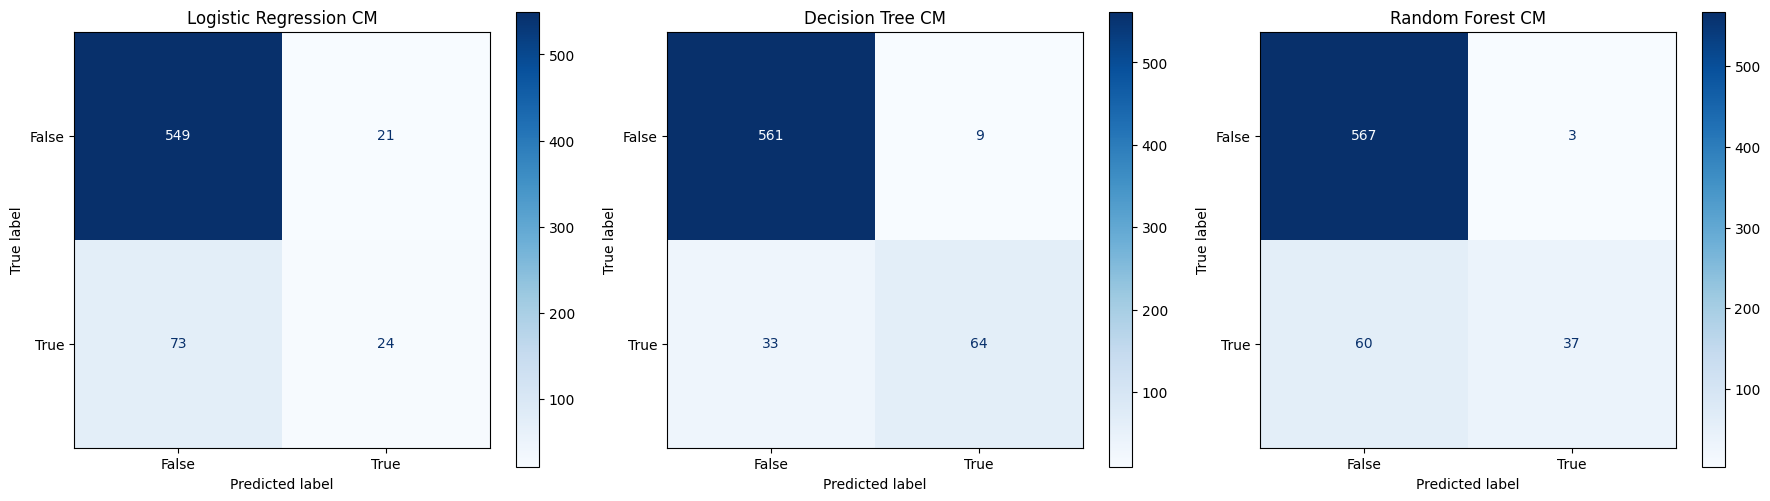

In [6]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

results = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(models.items()):
    # Create a full pipeline with preprocessor and model
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Fit the model
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Check if model supports predict_proba for ROC AUC
    if hasattr(pipeline, "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob)
    else:
        roc_auc = None

    # Store metrics
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='binary', pos_label=1 if 1 in y.values or 'Yes' in y.values else y.unique()[0]),
        'Recall': recall_score(y_test, y_pred, average='binary', pos_label=1 if 1 in y.values or 'Yes' in y.values else y.unique()[0]),
        'F1-Score': f1_score(y_test, y_pred, average='binary', pos_label=1 if 1 in y.values or 'Yes' in y.values else y.unique()[0]),
        'ROC-AUC': roc_auc
    }

    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix Visualization
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline.classes_)
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d')
    axes[idx].set_title(f"{name} CM")

plt.tight_layout()
plt.show()

### 4. Comparison of Models
Let's aggregate and visualize the evaluation metrics across all three algorithms to determine the best-performing model.

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.859070,0.533333,0.247423,0.338028,0.809387
Decision Tree,0.937031,0.876712,0.659794,0.752941,0.822002
Random Forest,0.905547,0.925000,0.381443,0.540146,0.894212


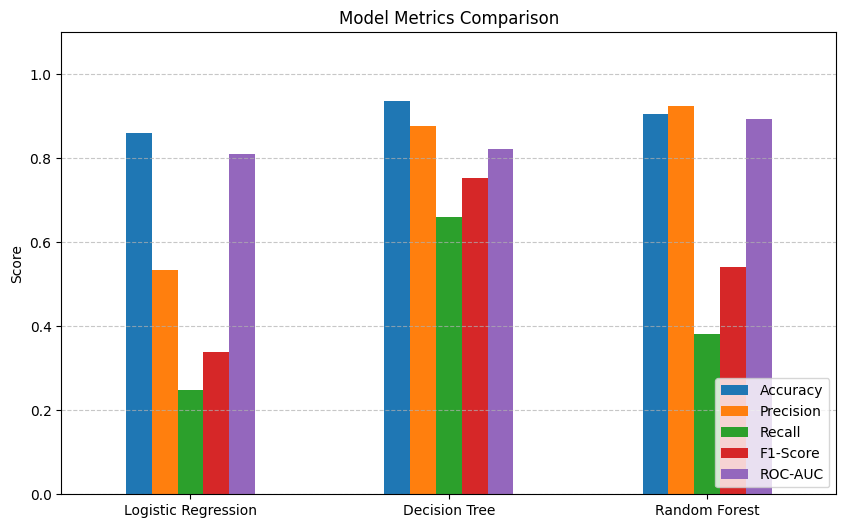

In [7]:
results_df = pd.DataFrame(results).T
display(results_df)

# Plot comparison
results_df.plot(kind='bar', figsize=(10, 6))
plt.title('Model Metrics Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()